In [ ]:
import pandas as pd
import numpy as np

# =========================
# 1. Load the two CSV files
# =========================
file1 = "AI Evaluation_Claude(Sheet1).csv"   # Rater 1
file2 = "AI Evaluation_GPT(Sheet1).csv"      # Rater 2

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

# =========================
# 2. Clean column names
# =========================
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# =========================
# 3. Keep only valid rows
# =========================
df1 = df1[df1["ID"].notna()].copy()
df2 = df2[df2["ID"].notna()].copy()

df1["ID"] = df1["ID"].astype(str).str.strip()
df2["ID"] = df2["ID"].astype(str).str.strip()

# =========================
# 4. Define the matrices
# =========================
metrics = ["HRO", "TCF", "PPA", "MA", "SPQ", "CSDC", "CER"]

our_cols = [f"{m}_Our" for m in metrics]
base_cols = [f"{m}_Base" for m in metrics]

# =========================
# TASK 1:
# Avg of each matrix separately for Rater 1
# =========================
rater1_our_avg = df1[our_cols].mean()
rater1_base_avg = df1[base_cols].mean()

task1_df = pd.DataFrame({
    "Metric": metrics,
    "Rater1_Our_Avg": [rater1_our_avg[f"{m}_Our"] for m in metrics],
    "Rater1_Base_Avg": [rater1_base_avg[f"{m}_Base"] for m in metrics]
})

print("\n=== TASK 1: Rater 1 average of each matrix ===")
print(task1_df.to_string(index=False))

# =========================
# TASK 2:
# Avg of each matrix separately for Rater 2
# =========================
rater2_our_avg = df2[our_cols].mean()
rater2_base_avg = df2[base_cols].mean()

task2_df = pd.DataFrame({
    "Metric": metrics,
    "Rater2_Our_Avg": [rater2_our_avg[f"{m}_Our"] for m in metrics],
    "Rater2_Base_Avg": [rater2_base_avg[f"{m}_Base"] for m in metrics]
})

print("\n=== TASK 2: Rater 2 average of each matrix ===")
print(task2_df.to_string(index=False))

# =========================
# TASK 3:
# Per-dimension avg comparison across both raters
# =========================
task3_df = pd.DataFrame({
    "Metric": metrics,
    "Rater1_Our_Avg": [rater1_our_avg[f"{m}_Our"] for m in metrics],
    "Rater2_Our_Avg": [rater2_our_avg[f"{m}_Our"] for m in metrics],
    "Rater1_Base_Avg": [rater1_base_avg[f"{m}_Base"] for m in metrics],
    "Rater2_Base_Avg": [rater2_base_avg[f"{m}_Base"] for m in metrics]
})

print("\n=== TASK 3: Per-dimension averages for both raters ===")
print(task3_df.to_string(index=False))

# =========================
# TASK 4:
# Improvement % = ((Our Avg - Base Avg) / Base Avg) * 100
# For all matrices
# Done separately for each rater
# Also average across both raters
# =========================
task4_df = pd.DataFrame({
    "Metric": metrics,
    "Rater1_Our_Avg": [rater1_our_avg[f"{m}_Our"] for m in metrics],
    "Rater1_Base_Avg": [rater1_base_avg[f"{m}_Base"] for m in metrics],
    "Rater1_Improvement_%": [
        ((rater1_our_avg[f"{m}_Our"] - rater1_base_avg[f"{m}_Base"]) / rater1_base_avg[f"{m}_Base"]) * 100
        for m in metrics
    ],
    "Rater2_Our_Avg": [rater2_our_avg[f"{m}_Our"] for m in metrics],
    "Rater2_Base_Avg": [rater2_base_avg[f"{m}_Base"] for m in metrics],
    "Rater2_Improvement_%": [
        ((rater2_our_avg[f"{m}_Our"] - rater2_base_avg[f"{m}_Base"]) / rater2_base_avg[f"{m}_Base"]) * 100
        for m in metrics
    ]
})

# Average of the two raters' averages first, then improvement
task4_df["Combined_Our_Avg"] = (task4_df["Rater1_Our_Avg"] + task4_df["Rater2_Our_Avg"]) / 2
task4_df["Combined_Base_Avg"] = (task4_df["Rater1_Base_Avg"] + task4_df["Rater2_Base_Avg"]) / 2
task4_df["Combined_Improvement_%"] = (
    (task4_df["Combined_Our_Avg"] - task4_df["Combined_Base_Avg"]) / task4_df["Combined_Base_Avg"]
) * 100

# Round for clean output
task1_df = task1_df.round(3)
task2_df = task2_df.round(3)
task3_df = task3_df.round(3)
task4_df = task4_df.round(3)

print("\n=== TASK 4: Improvement % for all matrices ===")
print(task4_df[[
    "Metric",
    "Rater1_Improvement_%",
    "Rater2_Improvement_%",
    "Combined_Improvement_%"
]].to_string(index=False))

# =========================
# Optional: Save outputs to Excel
# =========================
with pd.ExcelWriter("matrix_average_and_improvement_results.xlsx", engine="openpyxl") as writer:
    task1_df.to_excel(writer, sheet_name="Task1_Rater1_Avg", index=False)
    task2_df.to_excel(writer, sheet_name="Task2_Rater2_Avg", index=False)
    task3_df.to_excel(writer, sheet_name="Task3_Both_Raters", index=False)
    task4_df.to_excel(writer, sheet_name="Task4_Improvement", index=False)

print("\nSaved file: matrix_average_and_improvement_results.xlsx")


=== TASK 1: Rater 1 average of each matrix ===
Metric  Rater1_Our_Avg  Rater1_Base_Avg
   HRO       21.633333        15.566667
   TCF       11.700000         9.433333
   PPA       13.200000         9.633333
    MA        8.766667         7.100000
   SPQ        9.066667         6.633333
  CSDC       13.700000        11.333333
   CER        9.500000         4.733333

=== TASK 2: Rater 2 average of each matrix ===
Metric  Rater2_Our_Avg  Rater2_Base_Avg
   HRO       22.900000        18.200000
   TCF       13.766667        11.466667
   PPA       14.700000        11.433333
    MA        9.833333         7.766667
   SPQ        9.766667         7.733333
  CSDC       14.600000        11.433333
   CER        9.900000         6.833333

=== TASK 3: Per-dimension averages for both raters ===
Metric  Rater1_Our_Avg  Rater2_Our_Avg  Rater1_Base_Avg  Rater2_Base_Avg
   HRO       21.633333       22.900000        15.566667        18.200000
   TCF       11.700000       13.766667         9.433333       

# **Final improvement table**

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

# =========================
# 1. Load files
# =========================
file1 = "AI Evaluation_Claude(Sheet1).csv"   # Claude rater
file2 = "AI Evaluation_GPT(Sheet1).csv"      # GPT rater

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

# =========================
# 2. Clean columns and rows
# =========================
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

df1 = df1[df1["ID"].notna()].copy()
df2 = df2[df2["ID"].notna()].copy()

df1["ID"] = df1["ID"].astype(str).str.strip()
df2["ID"] = df2["ID"].astype(str).str.strip()

# =========================
# 3. Define dimensions and weights
# =========================
dimensions = ["HRO", "TCF", "PPA", "MA", "SPQ", "CSDC", "CER"]
weights = {
    "HRO": 25,
    "TCF": 15,
    "PPA": 15,
    "MA": 10,
    "SPQ": 10,
    "CSDC": 15,
    "CER": 10
}

# =========================
# 4. Build summary table
# =========================
# =========================
# 5. Raw total row (out of 100)
# =========================

total_system_claude_mean = df1["Total_Our"].mean()
total_system_claude_std = df1["Total_Our"].std()

total_system_gpt_mean = df2["Total_Our"].mean()
total_system_gpt_std = df2["Total_Our"].std()

combined_total_system = pd.concat([
    df1["Total_Our"],
    df2["Total_Our"]
])

total_system_avg_mean = combined_total_system.mean()
total_system_avg_std = combined_total_system.std()

total_baseline_claude_mean = df1["Total_Base"].mean()
total_baseline_claude_std = df1["Total_Base"].std()

total_baseline_gpt_mean = df2["Total_Base"].mean()
total_baseline_gpt_std = df2["Total_Base"].std()

combined_total_baseline = pd.concat([
    df1["Total_Base"],
    df2["Total_Base"]
])

total_baseline_avg_mean = combined_total_baseline.mean()
total_baseline_avg_std = combined_total_baseline.std()

total_improvement = (
    (total_system_avg_mean - total_baseline_avg_mean)
    / total_baseline_avg_mean
) * 100

weighted_row = pd.DataFrame([{
    "Dimension": "Raw Total",
    "Weight": "100%",

    "System\n(Claude)":
        f"{total_system_claude_mean:.2f} ± {total_system_claude_std:.2f}",

    "System\n(GPT)":
        f"{total_system_gpt_mean:.2f} ± {total_system_gpt_std:.2f}",

    "System\nAvg":
        f"{total_system_avg_mean:.2f} ± {total_system_avg_std:.2f}",

    "Baseline\n(Claude)":
        f"{total_baseline_claude_mean:.2f} ± {total_baseline_claude_std:.2f}",

    "Baseline\n(GPT)":
        f"{total_baseline_gpt_mean:.2f} ± {total_baseline_gpt_std:.2f}",

    "Baseline\nAvg":
        f"{total_baseline_avg_mean:.2f} ± {total_baseline_avg_std:.2f}",

    "Improvement": f"{total_improvement:+.1f}%"
}])
final_df = pd.concat([summary_df, weighted_row], ignore_index=True)

# =========================
# 6. Round numeric columns
# =========================
numeric_cols = [
    "System\n(Claude)", "System\n(GPT)", "System\nAvg",
    "Baseline\n(Claude)", "Baseline\n(GPT)", "Baseline\nAvg"
]


# =========================
# 7. Display a nice styled table
# =========================
styled_table = (
    final_df.style
    .hide(axis="index")
    .set_caption("Average Scores and Improvement by Dimension")
    .set_table_styles([
        {"selector": "caption",
         "props": [("caption-side", "top"),
                   ("font-size", "16px"),
                   ("font-weight", "bold"),
                   ("text-align", "center"),
                   ("padding", "10px")]},
        {"selector": "th",
         "props": [("text-align", "center"),
                   ("font-weight", "bold"),
                   ("font-size", "13px"),
                   ("border-bottom", "2px solid black"),
                   ("padding", "8px")]},
        {"selector": "td",
         "props": [("text-align", "center"),
                   ("padding", "8px"),
                   ("font-size", "13px")]},
        {"selector": "tbody tr:last-child td",
         "props": [("font-weight", "bold"),
                   ("border-top", "2px solid black")]},
        {"selector": "table",
         "props": [("border-collapse", "collapse"),
                   ("margin", "0 auto")]}
    ])
)

display(styled_table)

# =========================
# 8. Save to Excel
# =========================
final_df.to_excel("dimension_summary_table.xlsx", index=False)
print("Saved: dimension_summary_table.xlsx")

Dimension,Weight,System (Claude),System (GPT),System Avg,Baseline (Claude),Baseline (GPT),Baseline Avg,Improvement
HRO,25%,21.63 ± 1.08,22.90 ± 1.04,22.27 ± 1.23,15.57 ± 2.26,18.20 ± 1.40,16.88 ± 2.29,+31.9%
TCF,15%,11.70 ± 1.04,13.77 ± 1.36,12.73 ± 1.59,9.43 ± 1.73,11.47 ± 2.01,10.45 ± 2.12,+21.9%
PPA,15%,13.20 ± 0.70,14.70 ± 0.53,13.95 ± 0.97,9.63 ± 0.91,11.43 ± 1.73,10.53 ± 1.64,+32.4%
MA,10%,8.77 ± 0.62,9.83 ± 0.37,9.30 ± 0.74,7.10 ± 0.94,7.77 ± 0.99,7.43 ± 1.02,+25.1%
SPQ,10%,9.07 ± 0.81,9.77 ± 0.62,9.42 ± 0.80,6.63 ± 0.84,7.73 ± 0.57,7.18 ± 0.90,+31.1%
CSDC,15%,13.70 ± 1.22,14.60 ± 0.92,14.15 ± 1.16,11.33 ± 1.74,11.43 ± 1.56,11.38 ± 1.64,+24.3%
CER,10%,9.50 ± 0.81,9.90 ± 0.40,9.70 ± 0.66,4.73 ± 1.41,6.83 ± 0.97,5.78 ± 1.60,+67.7%
Raw Total,100%,87.57 ± 4.36,95.47 ± 3.38,91.52 ± 5.55,64.43 ± 5.64,74.87 ± 6.59,69.65 ± 8.04,+31.4%


Saved: dimension_summary_table.xlsx


In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

# =========================
# 1. Load files
# =========================
file1 = "AI Evaluation_Claude(Sheet1).csv"   # Claude rater
file2 = "AI Evaluation_GPT(Sheet1).csv"      # GPT rater

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

# =========================
# 2. Clean columns and rows
# =========================
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

df1 = df1[df1["ID"].notna()].copy()
df2 = df2[df2["ID"].notna()].copy()

df1["ID"] = df1["ID"].astype(str).str.strip()
df2["ID"] = df2["ID"].astype(str).str.strip()

# =========================
# Optional but recommended: Match common IDs
# =========================
df1 = df1.set_index("ID")
df2 = df2.set_index("ID")
common_ids = sorted(df1.index.intersection(df2.index))
df1 = df1.loc[common_ids].copy()
df2 = df2.loc[common_ids].copy()

# =========================
# 3. Define dimensions and weights
# =========================
dimensions = ["HRO", "TCF", "PPA", "MA", "SPQ", "CSDC", "CER"]
weights = {
    "HRO": 25,
    "TCF": 15,
    "PPA": 15,
    "MA": 10,
    "SPQ": 10,
    "CSDC": 15,
    "CER": 10
}

# =========================
# 4. Build summary table (Added missing logic with STD)
# =========================
rows_summary = []
for dim in dimensions:
    weight = weights[dim]

    # Claude (Rater 1)
    sys_claude_m, sys_claude_s = df1[f"{dim}_Our"].mean(), df1[f"{dim}_Our"].std()
    base_claude_m, base_claude_s = df1[f"{dim}_Base"].mean(), df1[f"{dim}_Base"].std()

    # GPT (Rater 2)
    sys_gpt_m, sys_gpt_s = df2[f"{dim}_Our"].mean(), df2[f"{dim}_Our"].std()
    base_gpt_m, base_gpt_s = df2[f"{dim}_Base"].mean(), df2[f"{dim}_Base"].std()

    # Pooled Averages
    pooled_sys = pd.concat([df1[f"{dim}_Our"], df2[f"{dim}_Our"]])
    sys_avg_m, sys_avg_s = pooled_sys.mean(), pooled_sys.std()

    pooled_base = pd.concat([df1[f"{dim}_Base"], df2[f"{dim}_Base"]])
    base_avg_m, base_avg_s = pooled_base.mean(), pooled_base.std()

    # Improvement calculation on raw floats
    improvement_pct = ((sys_avg_m - base_avg_m) / base_avg_m) * 100

    rows_summary.append({
        "Dimension": dim,
        "Weight": f"{weight}%",
        "System\n(Claude)": f"{sys_claude_m:.2f} ± {sys_claude_s:.2f}",
        "System\n(GPT)": f"{sys_gpt_m:.2f} ± {sys_gpt_s:.2f}",
        "System\nAvg": f"{sys_avg_m:.2f} ± {sys_avg_s:.2f}",
        "Baseline\n(Claude)": f"{base_claude_m:.2f} ± {base_claude_s:.2f}",
        "Baseline\n(GPT)": f"{base_gpt_m:.2f} ± {base_gpt_s:.2f}",
        "Baseline\nAvg": f"{base_avg_m:.2f} ± {base_avg_s:.2f}",
        "Improvement": f"{improvement_pct:+.1f}%"
    })

summary_df = pd.DataFrame(rows_summary)

# =========================
# 5. Raw total row (out of 100)
# =========================
total_system_claude_mean = df1["Total_Our"].mean()
total_system_claude_std = df1["Total_Our"].std()

total_system_gpt_mean = df2["Total_Our"].mean()
total_system_gpt_std = df2["Total_Our"].std()

combined_total_system = pd.concat([df1["Total_Our"], df2["Total_Our"]])
total_system_avg_mean = combined_total_system.mean()
total_system_avg_std = combined_total_system.std()

total_baseline_claude_mean = df1["Total_Base"].mean()
total_baseline_claude_std = df1["Total_Base"].std()

total_baseline_gpt_mean = df2["Total_Base"].mean()
total_baseline_gpt_std = df2["Total_Base"].std()

combined_total_baseline = pd.concat([df1["Total_Base"], df2["Total_Base"]])
total_baseline_avg_mean = combined_total_baseline.mean()
total_baseline_avg_std = combined_total_baseline.std()

total_improvement = (
    (total_system_avg_mean - total_baseline_avg_mean)
    / total_baseline_avg_mean
) * 100

weighted_row = pd.DataFrame([{
    "Dimension": "Raw Total",
    "Weight": "100%",
    "System\n(Claude)": f"{total_system_claude_mean:.2f} ± {total_system_claude_std:.2f}",
    "System\n(GPT)": f"{total_system_gpt_mean:.2f} ± {total_system_gpt_std:.2f}",
    "System\nAvg": f"{total_system_avg_mean:.2f} ± {total_system_avg_std:.2f}",
    "Baseline\n(Claude)": f"{total_baseline_claude_mean:.2f} ± {total_baseline_claude_std:.2f}",
    "Baseline\n(GPT)": f"{total_baseline_gpt_mean:.2f} ± {total_baseline_gpt_std:.2f}",
    "Baseline\nAvg": f"{total_baseline_avg_mean:.2f} ± {total_baseline_avg_std:.2f}",
    "Improvement": f"{total_improvement:+.1f}%"
}])

final_df = pd.concat([summary_df, weighted_row], ignore_index=True)

# =========================
# 7. Display a nice styled table
# =========================
styled_table = (
    final_df.style
    .hide(axis="index")
    .set_caption("Average Scores and Improvement by Dimension (Mean ± STD)")
    .set_table_styles([
        {"selector": "caption",
         "props": [("caption-side", "top"),
                   ("font-size", "16px"),
                   ("font-weight", "bold"),
                   ("text-align", "center"),
                   ("padding", "10px")]},
        {"selector": "th",
         "props": [("text-align", "center"),
                   ("font-weight", "bold"),
                   ("font-size", "13px"),
                   ("border-bottom", "2px solid black"),
                   ("padding", "8px"),
                   ("white-space", "pre-wrap")]}, # Added to handle \n in headers
        {"selector": "td",
         "props": [("text-align", "center"),
                   ("padding", "8px"),
                   ("font-size", "13px")]},
        {"selector": "tbody tr:last-child td",
         "props": [("font-weight", "bold"),
                   ("border-top", "2px solid black")]},
        {"selector": "table",
         "props": [("border-collapse", "collapse"),
                   ("margin", "0 auto")]}
    ])
)

display(styled_table)

# =========================
# 8. Save to Excel
# =========================
final_df.to_excel("dimension_summary_table.xlsx", index=False)
print("Saved: dimension_summary_table.xlsx")

Dimension,Weight,System (Claude),System (GPT),System Avg,Baseline (Claude),Baseline (GPT),Baseline Avg,Improvement
HRO,25%,21.63 ± 1.08,22.90 ± 1.04,22.27 ± 1.23,15.57 ± 2.26,18.20 ± 1.40,16.88 ± 2.29,+31.9%
TCF,15%,11.70 ± 1.04,13.77 ± 1.36,12.73 ± 1.59,9.43 ± 1.73,11.47 ± 2.01,10.45 ± 2.12,+21.9%
PPA,15%,13.20 ± 0.70,14.70 ± 0.53,13.95 ± 0.97,9.63 ± 0.91,11.43 ± 1.73,10.53 ± 1.64,+32.4%
MA,10%,8.77 ± 0.62,9.83 ± 0.37,9.30 ± 0.74,7.10 ± 0.94,7.77 ± 0.99,7.43 ± 1.02,+25.1%
SPQ,10%,9.07 ± 0.81,9.77 ± 0.62,9.42 ± 0.80,6.63 ± 0.84,7.73 ± 0.57,7.18 ± 0.90,+31.1%
CSDC,15%,13.70 ± 1.22,14.60 ± 0.92,14.15 ± 1.16,11.33 ± 1.74,11.43 ± 1.56,11.38 ± 1.64,+24.3%
CER,10%,9.50 ± 0.81,9.90 ± 0.40,9.70 ± 0.66,4.73 ± 1.41,6.83 ± 0.97,5.78 ± 1.60,+67.7%
Raw Total,100%,87.57 ± 4.36,95.47 ± 3.38,91.52 ± 5.55,64.43 ± 5.64,74.87 ± 6.59,69.65 ± 8.04,+31.4%


Saved: dimension_summary_table.xlsx


**leniency bias**

In [ ]:
import pandas as pd

# =========================
# 1. Load files
# =========================
file1 = "AI Evaluation_Claude(Sheet1).csv"   # Rater 1
file2 = "AI Evaluation_GPT(Sheet1).csv"      # Rater 2

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

# =========================
# 2. Clean data
# =========================
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

df1 = df1[df1["ID"].notna()].copy()
df2 = df2[df2["ID"].notna()].copy()

df1["ID"] = df1["ID"].astype(str).str.strip()
df2["ID"] = df2["ID"].astype(str).str.strip()

# =========================
# 3. Match IDs (VERY IMPORTANT)
# =========================
df1 = df1.set_index("ID")
df2 = df2.set_index("ID")

common_ids = df1.index.intersection(df2.index)

df1 = df1.loc[common_ids].sort_index()
df2 = df2.loc[common_ids].sort_index()

print("Matched IDs:", len(common_ids))

# =========================
# 4. Leniency Bias on TOTAL
# =========================

# Mean total scores
r1_total_our = df1["Total_Our"].mean()
r2_total_our = df2["Total_Our"].mean()

r1_total_base = df1["Total_Base"].mean()
r2_total_base = df2["Total_Base"].mean()

# Bias calculations
our_bias = r1_total_our - r2_total_our
base_bias = r1_total_base - r2_total_base

# Combined (Our + Base together)
r1_combined = pd.concat([df1["Total_Our"], df1["Total_Base"]]).mean()
r2_combined = pd.concat([df2["Total_Our"], df2["Total_Base"]]).mean()

combined_bias = r1_combined - r2_combined

# =========================
# 5. Show results
# =========================
result = pd.DataFrame([{
    "Rater1_Our_Total_Avg": round(r1_total_our, 2),
    "Rater2_Our_Total_Avg": round(r2_total_our, 2),
    "Our_Leniency_Bias": round(our_bias, 2),

    "Rater1_Base_Total_Avg": round(r1_total_base, 2),
    "Rater2_Base_Total_Avg": round(r2_total_base, 2),
    "Base_Leniency_Bias": round(base_bias, 2),

    "Rater1_Combined_Total_Avg": round(r1_combined, 2),
    "Rater2_Combined_Total_Avg": round(r2_combined, 2),
    "Combined_Leniency_Bias": round(combined_bias, 2)
}])

print("\n=== Leniency Bias (TOTAL Score out of 100) ===")
print(result.to_string(index=False))

# =========================
# 6. Interpretation
# =========================
print("\nInterpretation:")
print("Positive value  -> Rater 1 is more lenient (gives higher scores)")
print("Negative value  -> Rater 2 is more lenient")
print("Closer to 0     -> Both raters have similar scoring severity")

Matched IDs: 30

=== Leniency Bias (TOTAL Score out of 100) ===
 Rater1_Our_Total_Avg  Rater2_Our_Total_Avg  Our_Leniency_Bias  Rater1_Base_Total_Avg  Rater2_Base_Total_Avg  Base_Leniency_Bias  Rater1_Combined_Total_Avg  Rater2_Combined_Total_Avg  Combined_Leniency_Bias
                87.57                 95.47               -7.9                  64.43                  74.87              -10.43                       76.0                      85.17                   -9.17

Interpretation:
Positive value  -> Rater 1 is more lenient (gives higher scores)
Negative value  -> Rater 2 is more lenient
Closer to 0     -> Both raters have similar scoring severity


In [ ]:
# =========================
# 0. Install package
# =========================
!pip install pingouin -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 5.5 MB/s eta 0:00:00


**inter rater combined**

In [ ]:

# =========================
# 1. Imports
# =========================
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr
import pingouin as pg

# =========================
# 2. Load files
# =========================
file1 = "AI Evaluation_Claude(Sheet1).csv"   # Rater 1
file2 = "AI Evaluation_GPT(Sheet1).csv"      # Rater 2

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

# =========================
# 3. Clean data
# =========================
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

df1 = df1[df1["ID"].notna()].copy()
df2 = df2[df2["ID"].notna()].copy()

df1["ID"] = df1["ID"].astype(str).str.strip()
df2["ID"] = df2["ID"].astype(str).str.strip()

# =========================
# 4. Match common IDs
# =========================
df1 = df1.set_index("ID")
df2 = df2.set_index("ID")

common_ids = sorted(df1.index.intersection(df2.index))

df1 = df1.loc[common_ids].copy()
df2 = df2.loc[common_ids].copy()

print("Matched IDs:", len(common_ids))

# =========================
# 5. Choose score type
# Options:
#   "Total_Our"
#   "Total_Base"
#   "Combined"   -> Our + Base pooled together
# =========================
score_type = "Total_Base"   # change if needed

if score_type == "Total_Our":
    r1_scores = df1["Total_Our"].astype(float).values
    r2_scores = df2["Total_Our"].astype(float).values

    ids_for_corr = common_ids

    icc_df = pd.DataFrame({
        "ID": common_ids * 2,
        "Rater": ["Rater1"] * len(common_ids) + ["Rater2"] * len(common_ids),
        "Score": list(df1["Total_Our"].astype(float).values) + list(df2["Total_Our"].astype(float).values)
    })

elif score_type == "Total_Base":
    r1_scores = df1["Total_Base"].astype(float).values
    r2_scores = df2["Total_Base"].astype(float).values

    ids_for_corr = common_ids

    icc_df = pd.DataFrame({
        "ID": common_ids * 2,
        "Rater": ["Rater1"] * len(common_ids) + ["Rater2"] * len(common_ids),
        "Score": list(df1["Total_Base"].astype(float).values) + list(df2["Total_Base"].astype(float).values)
    })

elif score_type == "Combined":
    # Stack Our and Base together
    r1_scores = np.concatenate([
        df1["Total_Our"].astype(float).values,
        df1["Total_Base"].astype(float).values
    ])
    r2_scores = np.concatenate([
        df2["Total_Our"].astype(float).values,
        df2["Total_Base"].astype(float).values
    ])

    combined_ids = [f"{id_}_Our" for id_ in common_ids] + [f"{id_}_Base" for id_ in common_ids]

    icc_df = pd.DataFrame({
        "ID": combined_ids * 2,
        "Rater": ["Rater1"] * len(combined_ids) + ["Rater2"] * len(combined_ids),
        "Score": list(r1_scores) + list(r2_scores)
    })

else:
    raise ValueError("score_type must be 'Total_Our', 'Total_Base', or 'Combined'")

# =========================
# 6. Pearson and Spearman
# =========================
pearson_r, pearson_p = pearsonr(r1_scores, r2_scores)
spearman_rho, spearman_p = spearmanr(r1_scores, r2_scores)

corr_results = pd.DataFrame({
    "Metric": ["Pearson r", "Spearman rho"],
    "Coefficient": [pearson_r, spearman_rho],
    "p_value": [pearson_p, spearman_p]
}).round(4)

print(f"\n=== Correlation Results ({score_type}) ===")
print(corr_results.to_string(index=False))

# =========================
# 7. ICC
# =========================
icc_results = pg.intraclass_corr(
    data=icc_df,
    targets="ID",
    raters="Rater",
    ratings="Score"
)

icc_selected = icc_results[["Type", "ICC", "F", "df1", "df2", "pval", "CI95"]].copy()
icc_selected = icc_selected.round(4)

print(f"\n=== ICC Results ({score_type}) ===")
print(icc_selected.to_string(index=False))

Matched IDs: 30

=== Correlation Results (Total_Base) ===
      Metric  Coefficient  p_value
   Pearson r       0.4549   0.0115
Spearman rho       0.3167   0.0882

=== ICC Results (Total_Base) ===
    Type     ICC      F  df1  df2   pval          CI95
ICC(1,1) -0.1427 0.7502   29   30 0.7793 [-0.47, 0.22]
ICC(A,1)  0.1887 2.6328   29   29 0.0056 [-0.09, 0.51]
ICC(C,1)  0.4495 2.6328   29   29 0.0056  [0.11, 0.69]
ICC(1,k) -0.3330 0.7502   29   30 0.7793 [-1.78, 0.36]
ICC(A,k)  0.3175 2.6328   29   29 0.0056 [-0.21, 0.67]
ICC(C,k)  0.6202 2.6328   29   29 0.0056   [0.2, 0.82]


**inter rater 7 matrix combined**

In [ ]:

# =========================
# 1. Imports
# =========================
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr
import pingouin as pg

# =========================
# 2. Load files
# =========================
file1 = "AI Evaluation_Claude(Sheet1).csv"   # Rater 1
file2 = "AI Evaluation_GPT(Sheet1).csv"      # Rater 2

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

# =========================
# 3. Clean data
# =========================
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

df1 = df1[df1["ID"].notna()].copy()
df2 = df2[df2["ID"].notna()].copy()

df1["ID"] = df1["ID"].astype(str).str.strip()
df2["ID"] = df2["ID"].astype(str).str.strip()

# =========================
# 4. Match common IDs
# =========================
df1 = df1.set_index("ID")
df2 = df2.set_index("ID")

common_ids = sorted(df1.index.intersection(df2.index))

df1 = df1.loc[common_ids].copy()
df2 = df2.loc[common_ids].copy()

print("Matched IDs:", len(common_ids))

# =========================
# 5. Define all 7 dimensions
# =========================
dims = ["HRO", "TCF", "PPA", "MA", "SPQ", "CSDC", "CER"]

# =========================================================
# PART A: 7-Dim Combined — Our System
# =========================================================
r1_our = []
r2_our = []
ids_our = []

for d in dims:
    for id_ in common_ids:
        r1_our.append(df1.loc[id_, f"{d}_Our"])
        r2_our.append(df2.loc[id_, f"{d}_Our"])
        ids_our.append(f"{id_}_{d}")

r1_our = np.array(r1_our, dtype=float)
r2_our = np.array(r2_our, dtype=float)

print("\nTotal paired observations for Our System:", len(r1_our))

# Pearson and Spearman
pearson_our, pearson_our_p = pearsonr(r1_our, r2_our)
spearman_our, spearman_our_p = spearmanr(r1_our, r2_our)

print("\n=== 7-Dim Combined — Our System ===")
print(f"Pearson r   : {pearson_our:.4f} (p = {pearson_our_p:.4f})")
print(f"Spearman ρ  : {spearman_our:.4f} (p = {spearman_our_p:.4f})")

# ICC dataframe
icc_df_our = pd.DataFrame({
    "ID": ids_our * 2,
    "Rater": ["Rater1"] * len(ids_our) + ["Rater2"] * len(ids_our),
    "Score": list(r1_our) + list(r2_our)
})

icc_our = pg.intraclass_corr(
    data=icc_df_our,
    targets="ID",
    raters="Rater",
    ratings="Score"
)

icc_our = icc_our[["Type", "ICC", "F", "df1", "df2", "pval", "CI95"]].round(4)

print("\nICC Results — Our System")
print(icc_our.to_string(index=False))

# =========================================================
# PART B: 7-Dim Combined — Baseline
# =========================================================
r1_base = []
r2_base = []
ids_base = []

for d in dims:
    for id_ in common_ids:
        r1_base.append(df1.loc[id_, f"{d}_Base"])
        r2_base.append(df2.loc[id_, f"{d}_Base"])
        ids_base.append(f"{id_}_{d}")

r1_base = np.array(r1_base, dtype=float)
r2_base = np.array(r2_base, dtype=float)

print("\nTotal paired observations for Baseline:", len(r1_base))

# Pearson and Spearman
pearson_base, pearson_base_p = pearsonr(r1_base, r2_base)
spearman_base, spearman_base_p = spearmanr(r1_base, r2_base)

print("\n=== 7-Dim Combined — Baseline ===")
print(f"Pearson r   : {pearson_base:.4f} (p = {pearson_base_p:.4f})")
print(f"Spearman ρ  : {spearman_base:.4f} (p = {spearman_base_p:.4f})")

# ICC dataframe
icc_df_base = pd.DataFrame({
    "ID": ids_base * 2,
    "Rater": ["Rater1"] * len(ids_base) + ["Rater2"] * len(ids_base),
    "Score": list(r1_base) + list(r2_base)
})

icc_base = pg.intraclass_corr(
    data=icc_df_base,
    targets="ID",
    raters="Rater",
    ratings="Score"
)

icc_base = icc_base[["Type", "ICC", "F", "df1", "df2", "pval", "CI95"]].round(4)

print("\nICC Results — Baseline")
print(icc_base.to_string(index=False))


Matched IDs: 30

Total paired observations for Our System: 210

=== 7-Dim Combined — Our System ===
Pearson r   : 0.9606 (p = 0.0000)
Spearman ρ  : 0.9033 (p = 0.0000)

ICC Results — Our System
    Type    ICC       F  df1  df2  pval         CI95
ICC(1,1) 0.9276 26.6146  209  210   0.0 [0.91, 0.94]
ICC(A,1) 0.9288 48.9414  209  209   0.0 [0.65, 0.97]
ICC(C,1) 0.9600 48.9414  209  209   0.0 [0.95, 0.97]
ICC(1,k) 0.9624 26.6146  209  210   0.0 [0.95, 0.97]
ICC(A,k) 0.9631 48.9414  209  209   0.0 [0.79, 0.99]
ICC(C,k) 0.9796 48.9414  209  209   0.0 [0.97, 0.98]

Total paired observations for Baseline: 210

=== 7-Dim Combined — Baseline ===
Pearson r   : 0.8695 (p = 0.0000)
Spearman ρ  : 0.8528 (p = 0.0000)

ICC Results — Baseline
    Type    ICC       F  df1  df2  pval         CI95
ICC(1,1) 0.7973  8.8668  209  210   0.0 [0.74, 0.84]
ICC(A,1) 0.8047 14.1264  209  209   0.0 [0.47, 0.91]
ICC(C,1) 0.8678 14.1264  209  209   0.0  [0.83, 0.9]
ICC(1,k) 0.8872  8.8668  209  210   0.0 [0.85, 0.91

# **claude**

Upload the TWO CSV files when the dialog opens …


Saving AI Evaluation_GPT(Sheet1).csv to AI Evaluation_GPT(Sheet1) (1).csv
Saving AI Evaluation_Claude(Sheet1).csv to AI Evaluation_Claude(Sheet1) (1).csv

Rater 1 file : AI Evaluation_Claude(Sheet1) (1).csv  →  31 rows
Rater 2 file : AI Evaluation_GPT(Sheet1) (1).csv      →  32 rows

TASK 1 — Per-metric averages  |  Rater 1
Metric  Our_Avg_R1  Base_Avg_R1
   HRO   21.633333    15.566667
   TCF   11.700000     9.433333
   PPA   13.200000     9.633333
    MA    8.766667     7.100000
   SPQ    9.066667     6.633333
  CSDC   13.700000    11.333333
   CER    9.500000     4.733333

TASK 2 — Per-metric averages  |  Rater 2
Metric  Our_Avg_R2  Base_Avg_R2
   HRO   22.900000    18.200000
   TCF   13.766667    11.466667
   PPA   14.700000    11.433333
    MA    9.833333     7.766667
   SPQ    9.766667     7.733333
  CSDC   14.600000    11.433333
   CER    9.900000     6.833333

TASK 3 — Cross-rater per-dimension averages
Metric  Our_Avg_R1  Our_Avg_R2  Our_CrossRater_Avg  Base_Avg_R1  Base_Avg_R

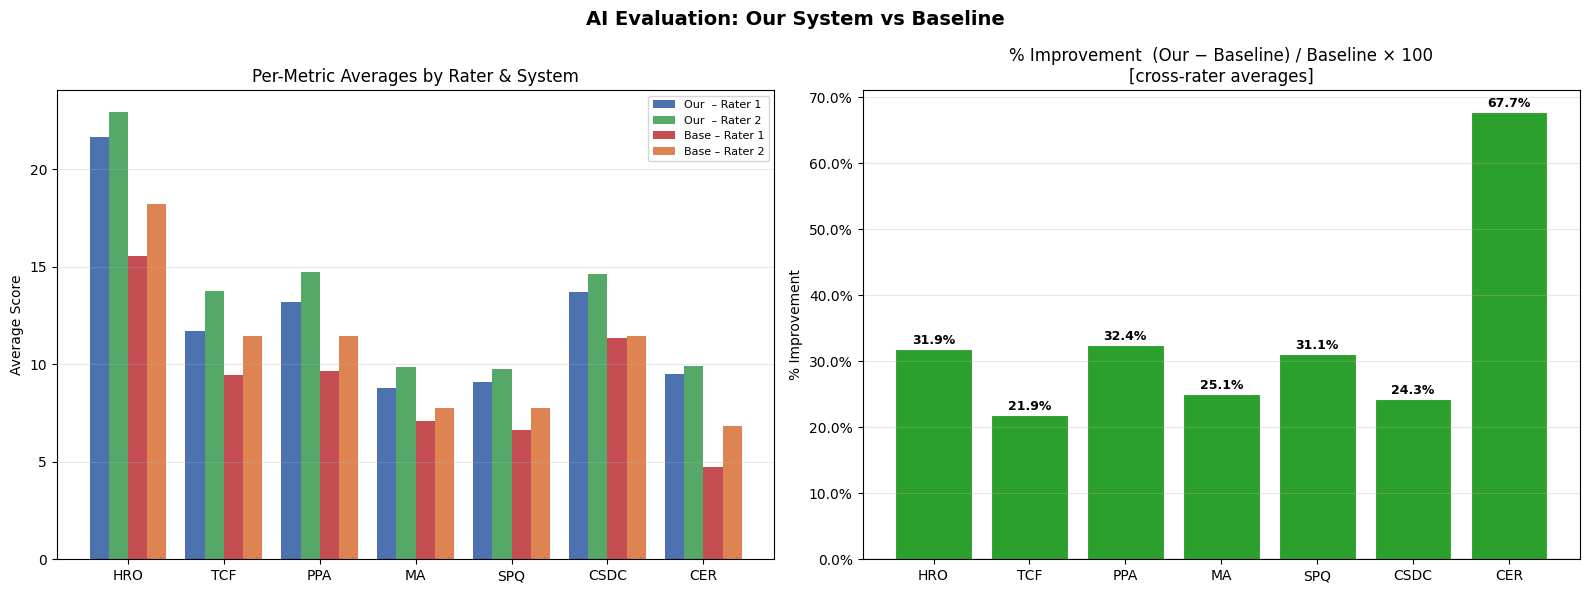


Chart saved as  AI_Evaluation_Results.png
Summary saved as  AI_Evaluation_Summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
#  AI Evaluation Analysis — Two Raters × Two Systems
#  Upload both CSVs when prompted (or adjust file paths)
# ============================================================

# ---------- 0. Install / import ----------
import pandas as pd
import numpy as np
from google.colab import files
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ---------- 1. Upload files ----------
print("Upload the TWO CSV files when the dialog opens …")
uploaded = files.upload()

file_names = list(uploaded.keys())
assert len(file_names) == 2, "Please upload exactly 2 CSV files."

# Identify which file belongs to which rater by name keyword
# (edit keywords if your file names differ)
claude_file = [f for f in file_names if "Claude" in f][0]
gpt_file    = [f for f in file_names if "GPT"    in f][0]

df1 = pd.read_csv(claude_file)   # Rater 1
df2 = pd.read_csv(gpt_file)      # Rater 2

print(f"\nRater 1 file : {claude_file}  →  {df1.shape[0]} rows")
print(f"Rater 2 file : {gpt_file}      →  {df2.shape[0]} rows")

# ---------- 2. Define dimensions ----------
METRICS = ["HRO", "TCF", "PPA", "MA", "SPQ", "CSDC", "CER"]

our_cols  = [f"{m}_Our"  for m in METRICS]
base_cols = [f"{m}_Base" for m in METRICS]

# ============================================================
#  TASK 1 — Per-metric averages for Rater 1
# ============================================================
print("\n" + "="*60)
print("TASK 1 — Per-metric averages  |  Rater 1")
print("="*60)

r1_our_avg  = df1[our_cols ].mean().rename(lambda c: c.replace("_Our",  ""))
r1_base_avg = df1[base_cols].mean().rename(lambda c: c.replace("_Base", ""))

task1 = pd.DataFrame({
    "Metric"      : METRICS,
    "Our_Avg_R1"  : r1_our_avg.values,
    "Base_Avg_R1" : r1_base_avg.values,
})
print(task1.to_string(index=False))

# ============================================================
#  TASK 2 — Per-metric averages for Rater 2
# ============================================================
print("\n" + "="*60)
print("TASK 2 — Per-metric averages  |  Rater 2")
print("="*60)

r2_our_avg  = df2[our_cols ].mean().rename(lambda c: c.replace("_Our",  ""))
r2_base_avg = df2[base_cols].mean().rename(lambda c: c.replace("_Base", ""))

task2 = pd.DataFrame({
    "Metric"      : METRICS,
    "Our_Avg_R2"  : r2_our_avg.values,
    "Base_Avg_R2" : r2_base_avg.values,
})
print(task2.to_string(index=False))

# ============================================================
#  TASK 3 — Cross-rater dimension averages
#            (average of Rater1 & Rater2 for each metric)
# ============================================================
print("\n" + "="*60)
print("TASK 3 — Cross-rater per-dimension averages")
print("="*60)

our_combined  = (r1_our_avg  + r2_our_avg)  / 2   # avg of both raters, Our system
base_combined = (r1_base_avg + r2_base_avg) / 2   # avg of both raters, Baseline

task3 = pd.DataFrame({
    "Metric"            : METRICS,
    "Our_Avg_R1"        : r1_our_avg.values,
    "Our_Avg_R2"        : r2_our_avg.values,
    "Our_CrossRater_Avg": our_combined.values,
    "Base_Avg_R1"       : r1_base_avg.values,
    "Base_Avg_R2"       : r2_base_avg.values,
    "Base_CrossRater_Avg": base_combined.values,
})
print(task3.to_string(index=False))

# ============================================================
#  TASK 4 — % Improvement  =  (Our − Base) / Base × 100
#           computed on the cross-rater averages
# ============================================================
print("\n" + "="*60)
print("TASK 4 — % Improvement  (Our vs Baseline, cross-rater avg)")
print("="*60)

pct_improvement = ((our_combined - base_combined) / base_combined) * 100

task4 = pd.DataFrame({
    "Metric"              : METRICS,
    "Our_CrossRater_Avg"  : our_combined.values.round(3),
    "Base_CrossRater_Avg" : base_combined.values.round(3),
    "Improvement_%"       : pct_improvement.values.round(2),
})
print(task4.to_string(index=False))

# ============================================================
#  COMBINED SUMMARY TABLE
# ============================================================
print("\n" + "="*60)
print("FULL SUMMARY TABLE")
print("="*60)

summary = task3.copy()
summary["Improvement_%"] = pct_improvement.values.round(2)
print(summary.to_string(index=False))

# ============================================================
#  VISUALISATION — % Improvement bar chart
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("AI Evaluation: Our System vs Baseline", fontsize=14, fontweight="bold")

# — Left: Raw averages grouped bar —
x  = np.arange(len(METRICS))
w  = 0.2

ax = axes[0]
ax.bar(x - 1.5*w, r1_our_avg.values,  w, label="Our  – Rater 1", color="#4C72B0")
ax.bar(x - 0.5*w, r2_our_avg.values,  w, label="Our  – Rater 2", color="#55A868")
ax.bar(x + 0.5*w, r1_base_avg.values, w, label="Base – Rater 1", color="#C44E52")
ax.bar(x + 1.5*w, r2_base_avg.values, w, label="Base – Rater 2", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(METRICS)
ax.set_ylabel("Average Score")
ax.set_title("Per-Metric Averages by Rater & System")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)

# — Right: % Improvement —
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in pct_improvement.values]
ax2 = axes[1]
bars = ax2.bar(METRICS, pct_improvement.values, color=colors, edgecolor="white", linewidth=0.8)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_ylabel("% Improvement")
ax2.set_title("% Improvement  (Our − Baseline) / Baseline × 100\n[cross-rater averages]")
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f%%"))
ax2.grid(axis="y", alpha=0.3)

for bar, val in zip(bars, pct_improvement.values):
    ypos = bar.get_height() + 0.3 if val >= 0 else bar.get_height() - 1.2
    ax2.text(bar.get_x() + bar.get_width()/2, ypos,
             f"{val:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("AI_Evaluation_Results.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nChart saved as  AI_Evaluation_Results.png")

# ============================================================
#  EXPORT full summary to CSV
# ============================================================
summary.to_csv("AI_Evaluation_Summary.csv", index=False)
print("Summary saved as  AI_Evaluation_Summary.csv")
files.download("AI_Evaluation_Summary.csv")
files.download("AI_Evaluation_Results.png")


1. PER-METRIC MEAN SCORES — Rater 1 vs Rater 2
Metric  Our_R1  Our_R2  Our_Diff(R1-R2)  Base_R1  Base_R2  Base_Diff(R1-R2)
   HRO  21.633  22.900           -1.267   15.567   18.200            -2.633
   TCF  11.700  13.767           -2.067    9.433   11.467            -2.033
   PPA  13.200  14.700           -1.500    9.633   11.433            -1.800
    MA   8.767   9.833           -1.067    7.100    7.767            -0.667
   SPQ   9.067   9.767           -0.700    6.633    7.733            -1.100
  CSDC  13.700  14.600           -0.900   11.333   11.433            -0.100
   CER   9.500   9.900           -0.400    4.733    6.833            -2.100

2. OVERALL LENIENCY BIAS (all metrics + both systems)
  Rater 1 global mean : 10.8571
  Rater 2 global mean : 12.1667
  Difference (R1−R2)  : -1.3095

  ➤ Verdict : Rater 2 is MORE LENIENT by 1.310 points on average.

3. PAIRED T-TEST PER METRIC (significance of leniency)
   H0: No difference between Rater 1 and Rater 2 scores
Metric   t-sta

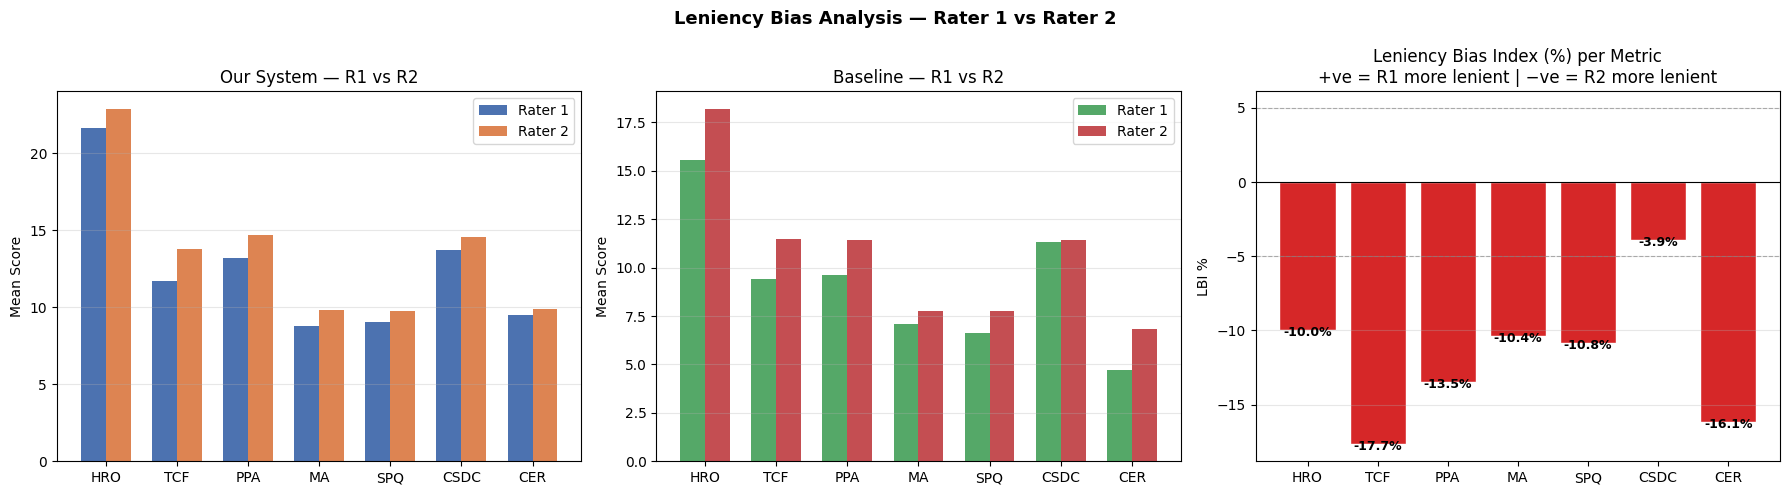


Chart saved as Leniency_Bias.png


In [ ]:
# ============================================================
#  LENIENCY BIAS ANALYSIS
#  Checks if one rater systematically scores higher than other
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files



file_names = list(uploaded.keys())
claude_file = [f for f in file_names if "Claude" in f][0]
gpt_file    = [f for f in file_names if "GPT"    in f][0]

df1 = pd.read_csv(claude_file)   # Rater 1
df2 = pd.read_csv(gpt_file)      # Rater 2

# --- Start of Added Code ---
# Clean column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Keep only valid rows
df1 = df1[df1["ID"].notna()].copy()
df2 = df2[df2["ID"].notna()].copy()

df1["ID"] = df1["ID"].astype(str).str.strip()
df2["ID"] = df2["ID"].astype(str).str.strip()

# Match IDs (VERY IMPORTANT)
df1 = df1.set_index("ID")
df2 = df2.set_index("ID")

common_ids = df1.index.intersection(df2.index)

df1 = df1.loc[common_ids].sort_index()
df2 = df2.loc[common_ids].sort_index()
# --- End of Added Code ---

METRICS = ["HRO", "TCF", "PPA", "MA", "SPQ", "CSDC", "CER"]
our_cols  = [f"{m}_Our"  for m in METRICS]
base_cols = [f"{m}_Base" for m in METRICS]

# ============================================================
#  1. Per-metric mean comparison (Rater 1 vs Rater 2)
# ============================================================
print("\n" + "="*65)
print("1. PER-METRIC MEAN SCORES — Rater 1 vs Rater 2")
print("="*65)

rows = []
for m in METRICS:
    r1_our  = df1[f"{m}_Our"].mean()
    r2_our  = df2[f"{m}_Our"].mean()
    r1_base = df1[f"{m}_Base"].mean()
    r2_base = df2[f"{m}_Base"].mean()
    rows.append({
        "Metric"      : m,
        "Our_R1"      : round(r1_our,  3),
        "Our_R2"      : round(r2_our,  3),
        "Our_Diff(R1-R2)"  : round(r1_our  - r2_our,  3),
        "Base_R1"     : round(r1_base, 3),
        "Base_R2"     : round(r2_base, 3),
        "Base_Diff(R1-R2)" : round(r1_base - r2_base, 3),
    })

bias_df = pd.DataFrame(rows)
print(bias_df.to_string(index=False))

# ============================================================
#  2. Overall leniency bias (across ALL metrics & ALL samples)
#     Leniency score per rater = mean of all their scores
# ============================================================
print("\n" + "="*65)
print("2. OVERALL LENIENCY BIAS (all metrics + both systems)")
print("="*65)

all_cols = our_cols + base_cols

r1_all_scores = df1[all_cols].values.flatten()
r2_all_scores = df2[all_cols].values.flatten()

r1_global_mean = np.mean(r1_all_scores)
r2_global_mean = np.mean(r2_all_scores)
global_diff    = r1_global_mean - r2_global_mean

print(f"  Rater 1 global mean : {r1_global_mean:.4f}")
print(f"  Rater 2 global mean : {r2_global_mean:.4f}")
print(f"  Difference (R1−R2)  : {global_diff:.4f}")

if abs(global_diff) < 0.5:
    verdict = "Negligible bias — raters are well-calibrated."
elif global_diff > 0:
    verdict = f"Rater 1 is MORE LENIENT by {global_diff:.3f} points on average."
else:
    verdict = f"Rater 2 is MORE LENIENT by {abs(global_diff):.3f} points on average."

print(f"\n  ➤ Verdict : {verdict}")

# ============================================================
#  3. Paired t-test per metric (Our + Base combined per rater)
#     Tests if the mean difference is statistically significant
# ============================================================
print("\n" + "="*65)
print("3. PAIRED T-TEST PER METRIC (significance of leniency)")
print("   H0: No difference between Rater 1 and Rater 2 scores")
print("="*65)

ttest_rows = []
for m in METRICS:
    # combine Our + Base scores for that metric per sample
    r1_scores = df1[f"{m}_Our"].values + df1[f"{m}_Base"].values
    r2_scores = df2[f"{m}_Our"].values + df2[f"{m}_Base"].values

    t_stat, p_val = stats.ttest_rel(r1_scores, r2_scores)
    sig = "✓ Significant" if p_val < 0.05 else "✗ Not significant"
    ttest_rows.append({
        "Metric"   : m,
        "t-stat"   : round(t_stat, 4),
        "p-value"  : round(p_val,  4),
        "Result"   : sig
    })

ttest_df = pd.DataFrame(ttest_rows)
print(ttest_df.to_string(index=False))
print("\n  (p < 0.05 means the leniency gap for that metric is statistically significant)")

# ============================================================
#  4. Leniency Bias Index (LBI) per metric
#     LBI = (R1_mean − R2_mean) / ((R1_mean + R2_mean) / 2) × 100
#     Positive → R1 more lenient | Negative → R2 more lenient
# ============================================================
print("\n" + "="*65)
print("4. LENIENCY BIAS INDEX (LBI) per metric  [in %]")
print("   LBI = (R1 − R2) / mean(R1, R2) × 100")
print("="*65)

lbi_rows = []
for m in METRICS:
    r1_mean = (df1[f"{m}_Our"].mean() + df1[f"{m}_Base"].mean()) / 2
    r2_mean = (df2[f"{m}_Our"].mean() + df2[f"{m}_Base"].mean()) / 2
    lbi     = (r1_mean - r2_mean) / ((r1_mean + r2_mean) / 2) * 100
    lbi_rows.append({"Metric": m, "R1_avg": round(r1_mean,3),
                     "R2_avg": round(r2_mean,3), "LBI_%": round(lbi,2)})

lbi_df = pd.DataFrame(lbi_rows)
print(lbi_df.to_string(index=False))
print("\n  Interpretation: |LBI| < 5% → low bias | 5-10% → moderate | >10% → high bias")

# ============================================================
#  5. VISUALISATION
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Leniency Bias Analysis — Rater 1 vs Rater 2", fontsize=13, fontweight="bold")

x = np.arange(len(METRICS))
w = 0.35

# — Plot A: Our system scores R1 vs R2 —
ax = axes[0]
ax.bar(x - w/2, [df1[f"{m}_Our"].mean() for m in METRICS], w, label="Rater 1", color="#4C72B0")
ax.bar(x + w/2, [df2[f"{m}_Our"].mean() for m in METRICS], w, label="Rater 2", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_title("Our System — R1 vs R2")
ax.set_ylabel("Mean Score"); ax.legend(); ax.grid(axis="y", alpha=0.3)

# — Plot B: Baseline scores R1 vs R2 —
ax = axes[1]
ax.bar(x - w/2, [df1[f"{m}_Base"].mean() for m in METRICS], w, label="Rater 1", color="#55A868")
ax.bar(x + w/2, [df2[f"{m}_Base"].mean() for m in METRICS], w, label="Rater 2", color="#C44E52")
ax.set_xticks(x); ax.set_xticklabels(METRICS)
ax.set_title("Baseline — R1 vs R2")
ax.set_ylabel("Mean Score"); ax.legend(); ax.grid(axis="y", alpha=0.3)

# — Plot C: LBI % per metric —
ax = axes[2]
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in lbi_df["LBI_%"]]
bars = ax.bar(METRICS, lbi_df["LBI_%"][:len(METRICS)], color=colors, edgecolor="white")
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline( 5, color="gray", linewidth=0.8, linestyle="--", alpha=0.6)
ax.axhline(-5, color="gray", linewidth=0.8, linestyle="--", alpha=0.6)
ax.set_title("Leniency Bias Index (%) per Metric\n+ve = R1 more lenient | −ve = R2 more lenient")
ax.set_ylabel("LBI %"); ax.grid(axis="y", alpha=0.3)
for bar, val in zip(bars, lbi_df["LBI_%"]):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.1 if val >= 0 else bar.get_height() - 0.4,
            f"{val:.1f}%", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("Leniency_Bias.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nChart saved as Leniency_Bias.png")

# **leniency bias visu**

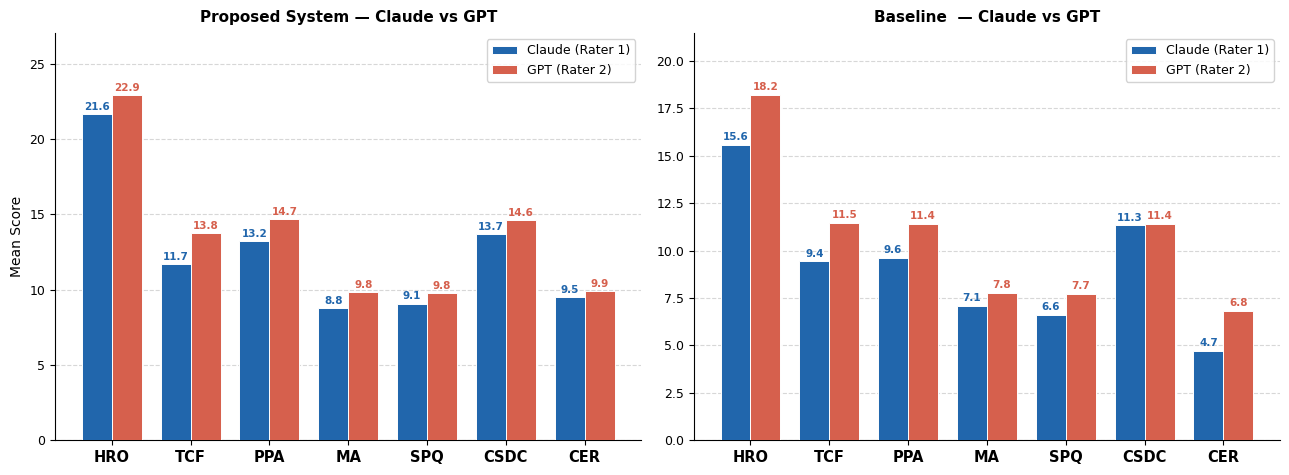

Saved: Leniency_Bias_Journal.png  +  .pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from google.colab import files

# ---------- Load files (skip upload if already done) ----------

claude_file = [f for f in file_names if "Claude" in f][0]
gpt_file    = [f for f in file_names if "GPT"    in f][0]

df1 = pd.read_csv(claude_file)   # Rater 1 — Claude
df2 = pd.read_csv(gpt_file)      # Rater 2 — GPT

METRICS = ["HRO", "TCF", "PPA", "MA", "SPQ", "CSDC", "CER"]

# ---------- Colors — journal-friendly ----------
C_CLAUDE = "#2166AC"   # deep blue   → Claude
C_GPT    = "#D6604D"   # muted red   → GPT

# ---------- Data ----------
our_claude  = [df1[f"{m}_Our"].mean()  for m in METRICS]
our_gpt     = [df2[f"{m}_Our"].mean()  for m in METRICS]
base_claude = [df1[f"{m}_Base"].mean() for m in METRICS]
base_gpt    = [df2[f"{m}_Base"].mean() for m in METRICS]

x = np.arange(len(METRICS))
w = 0.38

# ---------- Figure ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
fig.suptitle("",
             fontsize=13, fontweight="bold", y=1.02)

def styled_bar(ax, title, r1_vals, r2_vals, ylabel=True):
    bars1 = ax.bar(x - w/2, r1_vals, w, label="Claude (Rater 1)",
                   color=C_CLAUDE, edgecolor="white", linewidth=0.7, zorder=3)
    bars2 = ax.bar(x + w/2, r2_vals, w, label="GPT (Rater 2)",
                   color=C_GPT,    edgecolor="white", linewidth=0.7, zorder=3)

    # value labels on top of bars
    for bar in bars1:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                f"{bar.get_height():.1f}", ha="center", va="bottom",
                fontsize=7.5, color=C_CLAUDE, fontweight="bold")
    for bar in bars2:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                f"{bar.get_height():.1f}", ha="center", va="bottom",
                fontsize=7.5, color=C_GPT, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(METRICS, fontsize=10.5, fontweight="bold")
    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    if ylabel:
        ax.set_ylabel("Mean Score", fontsize=10)
    ax.tick_params(axis="y", labelsize=9)
    ax.set_ylim(0, max(max(r1_vals), max(r2_vals)) * 1.18)
    ax.yaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(fontsize=9, framealpha=0.85, loc="upper right")

styled_bar(axes[0], "Proposed System — Claude vs GPT",  our_claude,  our_gpt,  ylabel=True)
styled_bar(axes[1], "Baseline  — Claude vs GPT",   base_claude, base_gpt, ylabel=False)

plt.tight_layout(rect=[0, 0, 1, 1])

# ---------- Save (300 dpi for journal) ----------
plt.savefig("Leniency_Bias_Journal.png", dpi=300, bbox_inches="tight",
            facecolor="white", transparent=False)
plt.savefig("Leniency_Bias_Journal.pdf", bbox_inches="tight",
            facecolor="white", transparent=False)   # vector PDF — best for journals
plt.show()
print("Saved: Leniency_Bias_Journal.png  +  .pdf")
files.download("Leniency_Bias_Journal.png")
files.download("Leniency_Bias_Journal.pdf")

**inter rater relaibilit**

DF1 rows: 30  |  DF2 rows: 30
Combined obs — Our System : 210
Combined obs — Baseline   : 210

  7-Dim Combined — Our System  |  n = 210
  Metric         Value  95% CI                p-value   Sig  Interpretation
  ----------------------------------------------------------------------
  Pearson r     0.9606  [0.949, 0.970]         0.0000   ***  Excellent
  Spearman ρ    0.9033  [0.875, 0.925]         0.0000   ***  Excellent
  ----------------------------------------------------------------------
  ICC(1,1)      0.9276  [0.906, 0.944]         0.0000   ***  Excellent
  ICC(A,1)      0.9288  [0.948, 0.969]         0.0000   ***  Excellent
  ICC(C,1)      0.9600  [0.973, 0.984]         0.0000   ***  Excellent
  ICC(1,k)      0.9624  [0.906, 0.944]         0.0000   ***  Excellent
  ICC(A,k)      0.9631  [0.948, 0.969]         0.0000   ***  Excellent
  ICC(C,k)      0.9796  [0.973, 0.984]         0.0000   ***  Excellent

  ANOVA Table:
  Source                       SS     df         MS
  ---

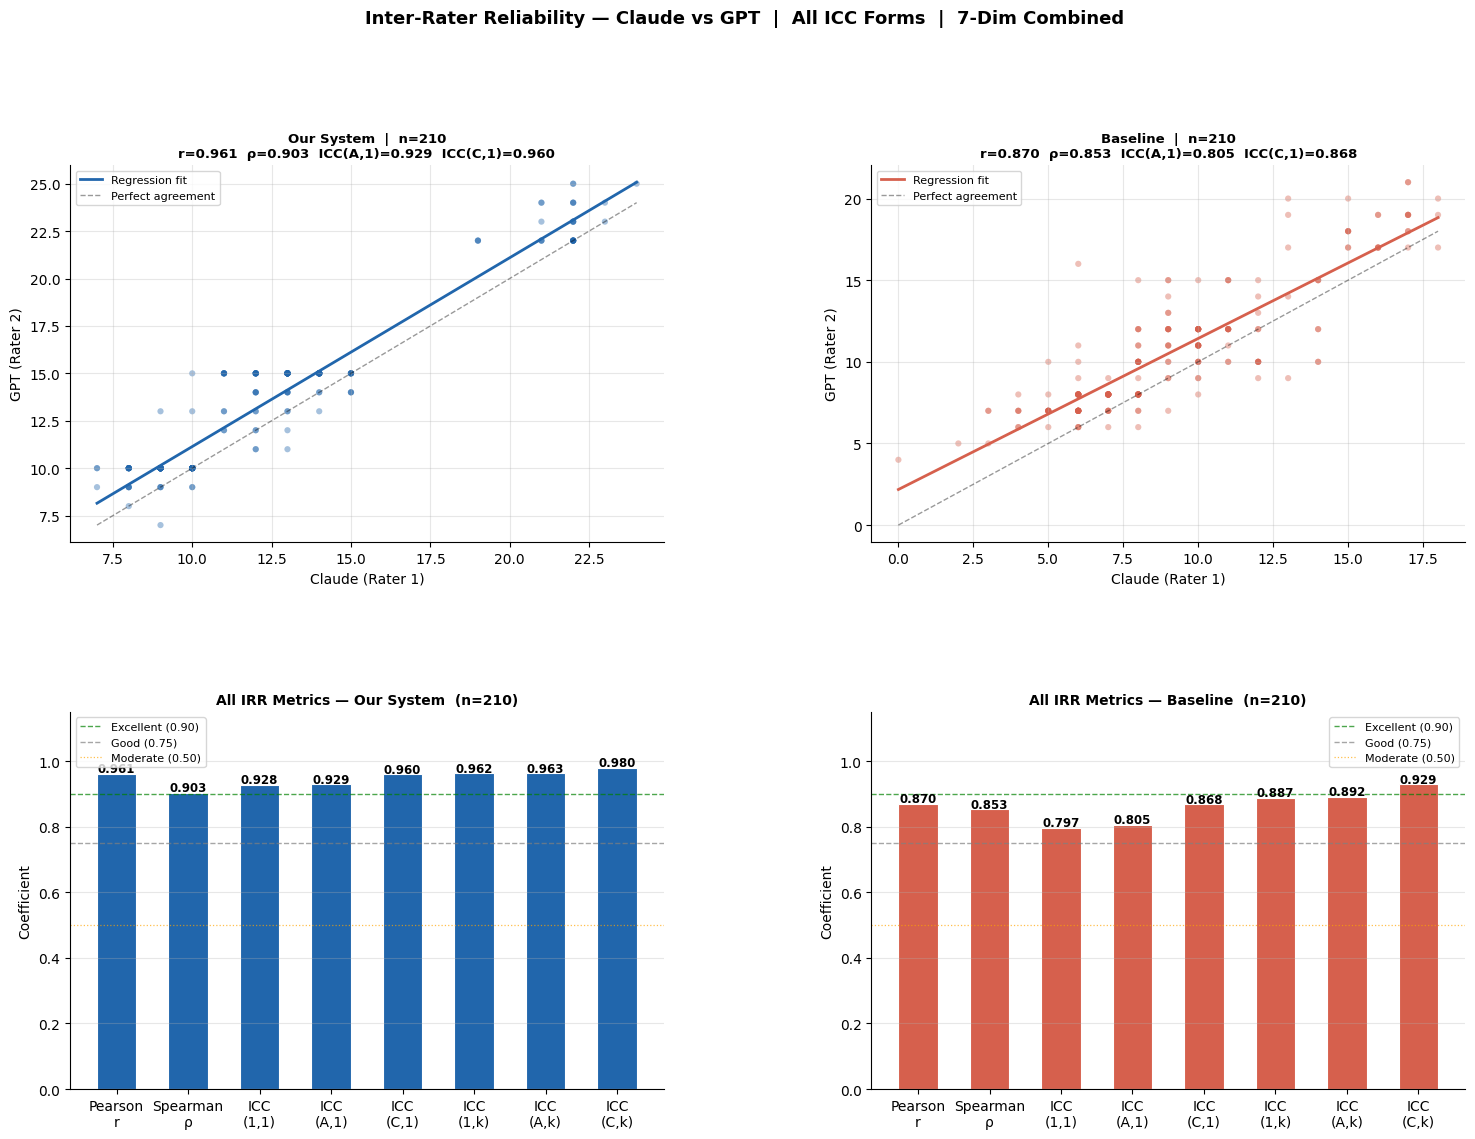


Saved: IRR_AllICC_Journal.png  +  IRR_AllICC_Journal.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
#  INTER-RATER RELIABILITY — All 6 ICC Forms
#  ICC(1,1), ICC(A,1), ICC(C,1), ICC(1,k), ICC(A,k), ICC(C,k)
#  + Pearson & Spearman
#  7-Dim Combined → 210 observations per system
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from google.colab import files

# -------- Upload --------

file_names  = list(uploaded.keys())
claude_file = [f for f in file_names if "Claude" in f][0]
gpt_file    = [f for f in file_names if "GPT"    in f][0]

df1 = pd.read_csv(claude_file)
df2 = pd.read_csv(gpt_file)

# -------- Drop empty rows --------
for df in [df1, df2]:
    df.dropna(subset=["ID"], inplace=True)
    df = df[df["ID"].astype(str).str.strip() != ""]

df1 = df1[df1["ID"].astype(str).str.strip() != ""].reset_index(drop=True)
df2 = df2[df2["ID"].astype(str).str.strip() != ""].reset_index(drop=True)
df1["ID"] = df1["ID"].astype(str).str.strip()
df2["ID"] = df2["ID"].astype(str).str.strip()

print(f"DF1 rows: {len(df1)}  |  DF2 rows: {len(df2)}")

METRICS = ["HRO", "TCF", "PPA", "MA", "SPQ", "CSDC", "CER"]

# ============================================================
#  Build long-format (210 obs)
# ============================================================
def build_long(df1, df2, suffix):
    cols   = ["ID"] + [f"{m}_{suffix}" for m in METRICS]
    merged = pd.merge(df1[cols], df2[cols], on="ID", suffixes=("_r1", "_r2"))
    rows   = []
    for _, row in merged.iterrows():
        for m in METRICS:
            rows.append({
                "obs_id" : f"{row['ID']}_{m}",
                "Rater1" : float(row[f"{m}_{suffix}_r1"]),
                "Rater2" : float(row[f"{m}_{suffix}_r2"]),
            })
    return pd.DataFrame(rows)

long_our  = build_long(df1, df2, "Our")
long_base = build_long(df1, df2, "Base")

print(f"Combined obs — Our System : {len(long_our)}")
print(f"Combined obs — Baseline   : {len(long_base)}")

# ============================================================
#  ALL 6 ICC FORMS — manual implementation
#
#  Notation:
#    n  = number of subjects (observations)
#    k  = number of raters (2)
#    MSb = Mean Square Between subjects
#    MSw = Mean Square Within subjects
#    MSe = Mean Square Error (interaction)
#    MSt = Mean Square Between raters (columns)
#
#  Forms:
#  ICC(1,1)  — One-way random, single,    consistency/absolute
#  ICC(A,1)  — Two-way random, single,    absolute agreement
#  ICC(C,1)  — Two-way mixed,  single,    consistency
#  ICC(1,k)  — One-way random, average,   consistency/absolute
#  ICC(A,k)  — Two-way random, average,   absolute agreement
#  ICC(C,k)  — Two-way mixed,  average,   consistency
# ============================================================

def all_icc(r1, r2):
    n      = len(r1)
    k      = 2
    data   = np.array([r1, r2], dtype=float).T    # (n, k)

    grand_mean = data.mean()
    row_means  = data.mean(axis=1)                 # subject means
    col_means  = data.mean(axis=0)                 # rater means

    SSb = k * np.sum((row_means  - grand_mean) ** 2)   # between subjects
    SSt = n * np.sum((col_means  - grand_mean) ** 2)   # between raters
    SSw = np.sum((data - row_means[:, None]) ** 2)      # within subjects
    SSe = SSw - SSt                                     # error (residual)

    dfb = n - 1
    dfw = n * (k - 1)
    dft = k - 1
    dfe = (n - 1) * (k - 1)

    MSb = SSb / dfb
    MSw = SSw / dfw
    MSe = SSe / dfe  if dfe  > 0 else 1e-10
    MSt = SSt / dft  if dft  > 0 else 1e-10

    # ---- ICC values ----
    # ICC(1,1)  one-way random, single measure
    icc_1_1  = (MSb - MSw) / (MSb + (k - 1) * MSw)

    # ICC(A,1)  two-way random, absolute agreement, single
    icc_A_1  = (MSb - MSe) / (MSb + (k-1)*MSe + k*(MSt - MSe)/n)

    # ICC(C,1)  two-way mixed, consistency, single
    icc_C_1  = (MSb - MSe) / (MSb + (k - 1) * MSe)

    # ICC(1,k)  one-way random, average measures
    icc_1_k  = (MSb - MSw) / MSb

    # ICC(A,k)  two-way random, absolute agreement, average
    icc_A_k  = (MSb - MSe) / (MSb + (MSt - MSe) / n)

    # ICC(C,k)  two-way mixed, consistency, average
    icc_C_k  = (MSb - MSe) / MSb

    # ---- Clip to [-1, 1] ----
    results = {}
    for name, val in [("ICC(1,1)", icc_1_1), ("ICC(A,1)", icc_A_1),
                      ("ICC(C,1)", icc_C_1), ("ICC(1,k)", icc_1_k),
                      ("ICC(A,k)", icc_A_k), ("ICC(C,k)", icc_C_k)]:
        results[name] = float(np.clip(val, -1, 1))

    # ---- 95% CI and p-value via F-test (for each form) ----
    alpha = 0.05
    ci_results = {}

    def f_ci(F_obs, df1_f, df2_f, k_val, form):
        FL = F_obs / stats.f.ppf(1 - alpha/2, df1_f, df2_f)
        FU = F_obs * stats.f.ppf(1 - alpha/2, df2_f, df1_f)
        p  = 1 - stats.f.cdf(F_obs, df1_f, df2_f)
        if form in ["ICC(1,1)", "ICC(1,k)"]:
            lo = (FL - 1) / (FL + k_val - 1)
            hi = (FU - 1) / (FU + k_val - 1)
        elif form in ["ICC(C,1)", "ICC(C,k)"]:
            lo = 1 - 1/FL
            hi = 1 - 1/FU
        else:   # absolute agreement forms — approximate
            lo = (FL - 1) / (FL + k_val - 1)
            hi = (FU - 1) / (FU + k_val - 1)
        return round(float(np.clip(lo,-1,1)),3), round(float(np.clip(hi,-1,1)),3), round(float(p),4)

    F_1  = MSb / MSw   if MSw  > 0 else np.inf
    F_A  = MSb / MSe   if MSe  > 0 else np.inf
    F_C  = MSb / MSe   if MSe  > 0 else np.inf

    ci_results["ICC(1,1)"] = f_ci(F_1, dfb, dfw, k, "ICC(1,1)")
    ci_results["ICC(A,1)"] = f_ci(F_A, dfb, dfe, k, "ICC(A,1)")
    ci_results["ICC(C,1)"] = f_ci(F_C, dfb, dfe, k, "ICC(C,1)")
    ci_results["ICC(1,k)"] = f_ci(F_1, dfb, dfw, k, "ICC(1,k)")
    ci_results["ICC(A,k)"] = f_ci(F_A, dfb, dfe, k, "ICC(A,k)")
    ci_results["ICC(C,k)"] = f_ci(F_C, dfb, dfe, k, "ICC(C,k)")

    return results, ci_results, {"MSb":MSb,"MSw":MSw,"MSe":MSe,"MSt":MSt,
                                  "SSb":SSb,"SSw":SSw,"SSe":SSe,"SSt":SSt,
                                  "dfb":dfb,"dfw":dfw,"dfe":dfe,"dft":dft}

def interpret(v):
    if   v < 0.50: return "Poor"
    elif v < 0.75: return "Moderate"
    elif v < 0.90: return "Good"
    else:          return "Excellent"

def sig_label(p):
    if   p < 0.001: return "***"
    elif p < 0.01:  return "**"
    elif p < 0.05:  return "*"
    else:           return "ns"

# ============================================================
#  Full reliability report
# ============================================================
ICC_FORMS = ["ICC(1,1)", "ICC(A,1)", "ICC(C,1)", "ICC(1,k)", "ICC(A,k)", "ICC(C,k)"]
ICC_DESC  = {
    "ICC(1,1)" : "One-way random,  single,  absolute",
    "ICC(A,1)" : "Two-way random,  single,  absolute agreement",
    "ICC(C,1)" : "Two-way mixed,   single,  consistency",
    "ICC(1,k)" : "One-way random,  average, absolute",
    "ICC(A,k)" : "Two-way random,  average, absolute agreement",
    "ICC(C,k)" : "Two-way mixed,   average, consistency",
}

def reliability_report(long_df, label):
    r1 = long_df["Rater1"].values
    r2 = long_df["Rater2"].values
    n  = len(r1)

    pear_r,  pear_p  = stats.pearsonr(r1, r2)
    spear_r, spear_p = stats.spearmanr(r1, r2)
    icc_vals, ci_vals, ms_vals = all_icc(r1, r2)

    print(f"\n{'='*72}")
    print(f"  {label}  |  n = {n}")
    print(f"{'='*72}")
    print(f"  {'Metric':<12} {'Value':>7}  {'95% CI':<18} {'p-value':>10}  {'Sig':>4}  Interpretation")
    print(f"  {'-'*70}")

    def prow(name, val, lo, hi, p):
        ci_str = f"[{lo:.3f}, {hi:.3f}]"
        print(f"  {name:<12} {val:>7.4f}  {ci_str:<18} {p:>10.4f}  {sig_label(p):>4}  {interpret(val)}")

    # Pearson CI via Fisher z
    z      = np.arctanh(pear_r)
    se_z   = 1 / np.sqrt(n - 3)
    z_crit = stats.norm.ppf(0.975)
    p_lo   = float(np.tanh(z - z_crit * se_z))
    p_hi   = float(np.tanh(z + z_crit * se_z))
    prow("Pearson r",  pear_r,  p_lo, p_hi, pear_p)

    # Spearman CI via Fisher z approximation
    zs     = np.arctanh(spear_r)
    s_lo   = float(np.tanh(zs - z_crit * se_z))
    s_hi   = float(np.tanh(zs + z_crit * se_z))
    prow("Spearman ρ", spear_r, s_lo, s_hi, spear_p)

    print(f"  {'-'*70}")
    for form in ICC_FORMS:
        lo, hi, p = ci_vals[form]
        prow(form, icc_vals[form], lo, hi, p)

    print(f"\n  ANOVA Table:")
    print(f"  {'Source':<20} {'SS':>10} {'df':>6} {'MS':>10}")
    print(f"  {'-'*50}")
    print(f"  {'Between subjects':<20} {ms_vals['SSb']:>10.3f} {ms_vals['dfb']:>6} {ms_vals['MSb']:>10.3f}")
    print(f"  {'Within subjects':<20} {ms_vals['SSw']:>10.3f} {ms_vals['dfw']:>6} {ms_vals['MSw']:>10.3f}")
    print(f"  {'  Between raters':<20} {ms_vals['SSt']:>10.3f} {ms_vals['dft']:>6} {ms_vals['MSt']:>10.3f}")
    print(f"  {'  Residual/Error':<20} {ms_vals['SSe']:>10.3f} {ms_vals['dfe']:>6} {ms_vals['MSe']:>10.3f}")
    print(f"{'='*72}")

    return {"label": label, "n": n,
            "Pearson_r": round(pear_r,4), "Spearman_rho": round(spear_r,4),
            **{f: round(icc_vals[f],4) for f in ICC_FORMS}}

res_our  = reliability_report(long_our,  "7-Dim Combined — Our System")
res_base = reliability_report(long_base, "7-Dim Combined — Baseline")

# ============================================================
#  VISUALISATION
# ============================================================
C1, C2   = "#2166AC", "#D6604D"
ALL_KEYS = ["Pearson_r", "Spearman_rho"] + ICC_FORMS
X_LABELS = ["Pearson\nr", "Spearman\nρ",
            "ICC\n(1,1)", "ICC\n(A,1)", "ICC\n(C,1)",
            "ICC\n(1,k)", "ICC\n(A,k)", "ICC\n(C,k)"]

fig = plt.figure(figsize=(18, 12))
gs  = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)

# ---- A: Scatter — Our System ----
ax0 = fig.add_subplot(gs[0, 0])
ax0.scatter(long_our["Rater1"], long_our["Rater2"],
            alpha=0.4, s=20, color=C1, edgecolors="none")
m_, b_ = np.polyfit(long_our["Rater1"], long_our["Rater2"], 1)
xr = np.linspace(long_our["Rater1"].min(), long_our["Rater1"].max(), 100)
ax0.plot(xr, m_*xr + b_, color=C1, linewidth=2,   label="Regression fit")
ax0.plot(xr, xr,         "k--",    linewidth=1,    alpha=0.4, label="Perfect agreement")
ax0.set_xlabel("Claude (Rater 1)", fontsize=10)
ax0.set_ylabel("GPT (Rater 2)",    fontsize=10)
ax0.set_title(f"Our System  |  n=210\n"
              f"r={res_our['Pearson_r']:.3f}  "
              f"ρ={res_our['Spearman_rho']:.3f}  "
              f"ICC(A,1)={res_our['ICC(A,1)']:.3f}  "
              f"ICC(C,1)={res_our['ICC(C,1)']:.3f}",
              fontsize=9.5, fontweight="bold")
ax0.legend(fontsize=8); ax0.grid(alpha=0.3)
ax0.spines["top"].set_visible(False); ax0.spines["right"].set_visible(False)

# ---- B: Scatter — Baseline ----
ax1 = fig.add_subplot(gs[0, 1])
ax1.scatter(long_base["Rater1"], long_base["Rater2"],
            alpha=0.4, s=20, color=C2, edgecolors="none")
m_, b_ = np.polyfit(long_base["Rater1"], long_base["Rater2"], 1)
xr = np.linspace(long_base["Rater1"].min(), long_base["Rater1"].max(), 100)
ax1.plot(xr, m_*xr + b_, color=C2, linewidth=2,   label="Regression fit")
ax1.plot(xr, xr,         "k--",    linewidth=1,    alpha=0.4, label="Perfect agreement")
ax1.set_xlabel("Claude (Rater 1)", fontsize=10)
ax1.set_ylabel("GPT (Rater 2)",    fontsize=10)
ax1.set_title(f"Baseline  |  n=210\n"
              f"r={res_base['Pearson_r']:.3f}  "
              f"ρ={res_base['Spearman_rho']:.3f}  "
              f"ICC(A,1)={res_base['ICC(A,1)']:.3f}  "
              f"ICC(C,1)={res_base['ICC(C,1)']:.3f}",
              fontsize=9.5, fontweight="bold")
ax1.legend(fontsize=8); ax1.grid(alpha=0.3)
ax1.spines["top"].set_visible(False); ax1.spines["right"].set_visible(False)

# ---- C: All metrics — Our System ----
ax2 = fig.add_subplot(gs[1, 0])
our_vals = [res_our[k] for k in ALL_KEYS]
colors_c = [C1 if v >= 0.75 else ("#F4A460" if v >= 0.50 else "#D62728") for v in our_vals]
bars = ax2.bar(X_LABELS, our_vals, color=colors_c, edgecolor="white", linewidth=0.8, width=0.55)
ax2.axhline(0.90, color="green", linestyle="--", lw=1,   alpha=0.7, label="Excellent (0.90)")
ax2.axhline(0.75, color="gray",  linestyle="--", lw=1,   alpha=0.7, label="Good (0.75)")
ax2.axhline(0.50, color="orange",linestyle=":",  lw=0.9, alpha=0.7, label="Moderate (0.50)")
for bar, val in zip(bars, our_vals):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.005,
             f"{val:.3f}", ha="center", fontsize=8.5, fontweight="bold")
ax2.set_ylim(0, 1.15); ax2.set_ylabel("Coefficient", fontsize=10)
ax2.set_title("All IRR Metrics — Our System  (n=210)",
              fontsize=10, fontweight="bold")
ax2.legend(fontsize=8); ax2.grid(axis="y", alpha=0.3)
ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False)

# ---- D: All metrics — Baseline ----
ax3 = fig.add_subplot(gs[1, 1])
base_vals = [res_base[k] for k in ALL_KEYS]
colors_d  = [C2 if v >= 0.75 else ("#F4A460" if v >= 0.50 else "#D62728") for v in base_vals]
bars = ax3.bar(X_LABELS, base_vals, color=colors_d, edgecolor="white", linewidth=0.8, width=0.55)
ax3.axhline(0.90, color="green", linestyle="--", lw=1,   alpha=0.7, label="Excellent (0.90)")
ax3.axhline(0.75, color="gray",  linestyle="--", lw=1,   alpha=0.7, label="Good (0.75)")
ax3.axhline(0.50, color="orange",linestyle=":",  lw=0.9, alpha=0.7, label="Moderate (0.50)")
for bar, val in zip(bars, base_vals):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.005,
             f"{val:.3f}", ha="center", fontsize=8.5, fontweight="bold")
ax3.set_ylim(0, 1.15); ax3.set_ylabel("Coefficient", fontsize=10)
ax3.set_title("All IRR Metrics — Baseline  (n=210)",
              fontsize=10, fontweight="bold")
ax3.legend(fontsize=8); ax3.grid(axis="y", alpha=0.3)
ax3.spines["top"].set_visible(False); ax3.spines["right"].set_visible(False)

fig.suptitle("Inter-Rater Reliability — Claude vs GPT  |  All ICC Forms  |  7-Dim Combined",
             fontsize=13, fontweight="bold", y=1.01)

plt.savefig("IRR_AllICC_Journal.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig("IRR_AllICC_Journal.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print("\nSaved: IRR_AllICC_Journal.png  +  IRR_AllICC_Journal.pdf")
files.download("IRR_AllICC_Journal.png")
files.download("IRR_AllICC_Journal.pdf")